In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load processed dataset
DATA_PATH = Path("../../data/processed/INX_employee_performance_processed.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape) 
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1200, 28)
Dataset loaded successfully!
Dataset shape: (1200, 28)


,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


In [2]:
# Separate features and target

x = df.drop(columns=["PerformanceRating", "EmpNumber"])
y = df["PerformanceRating"]

print("Features shape:", x.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Features shape: (1200, 26)
Target shape: (1200,)

Target distribution:
PerformanceRating
2    194
3    874
4    132
Name: count, dtype: int64


In [3]:
# Identify categorical and numerical columns

categorical_cols = x.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = x.select_dtypes(include=["number"]).columns.tolist()

print("Categorical columns:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical columns:", len(numerical_cols))
print(numerical_cols)

Categorical columns: 8
['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'OverTime', 'Attrition']

Numerical columns: 18
['Age', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [4]:
# check target class distribution
print("performance rating counts:")
print(y.value_counts().sort_index())
print("\nperformance rating percentage:")
print((y.value_counts(normalize=True).sort_index()*100).round(2))

performance rating counts:
PerformanceRating
2    194
3    874
4    132
Name: count, dtype: int64

performance rating percentage:
PerformanceRating
2    16.17
3    72.83
4    11.00
Name: proportion, dtype: float64


#### Target is imbalanced

### Train-test split

In [5]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("x_train shape:",x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:",y_test.shape)

x_train shape: (960, 26)
x_test shape: (240, 26)
y_train shape: (960,)
y_test shape: (240,)


In [6]:
categorical_col=x_train.select_dtypes(include=["object"]).columns.tolist()
Numerical_col=x_train.select_dtypes(include=np.number).columns.tolist()
print("categorical_col:",len(categorical_col))
print("Numerical_col:",len(Numerical_col))
print("Total col:",len(categorical_col) + len(Numerical_col))

categorical_col: 8
Numerical_col: 18
Total col: 26


## Machine Learning model Training

## 8. Model Building — Logistic Regression

### Objective
The objective of this step is to build a baseline classification model to predict employee performance ratings using employee-related features.

### Why Logistic Regression?
Logistic Regression is a supervised machine learning algorithm used for classification problems. In this project, it predicts one of three performance rating classes: 2, 3, or 4.

It is selected as the baseline model because it is simple, computationally efficient, and provides a reference for comparing other classification algorithms.

### Preprocessing
A `ColumnTransformer` is used to preprocess the input features:
- **StandardScaler:** Scales numerical features.
- **OneHotEncoder:** Converts categorical features into numerical representations.

A `Pipeline` combines preprocessing and Logistic Regression to ensure that the same transformations are applied consistently during training and prediction.

### Model Training
The model is trained using 80% of the dataset. The remaining 20% is reserved for testing. Stratified splitting maintains the original target-class proportions in both sets.

### Evaluation
The model is evaluated using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix. Macro F1-score and class-wise Recall are especially useful because the target classes are imbalanced.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),Numerical_col),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_col)
    ]
)
print("preprocessor created successfully")

preprocessor created successfully


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

In [9]:
logistic_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [10]:
y_pred = logistic_pipeline.predict(x_test)    # model predicted employee performance

In [11]:
y_pred[:10]

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3])

In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100, "%")

Accuracy: 0.825
Accuracy: 82.5 %


In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           2       0.61      0.49      0.54        39
           3       0.86      0.93      0.89       175
           4       0.84      0.62      0.71        26

    accuracy                           0.82       240
   macro avg       0.77      0.68      0.72       240
weighted avg       0.82      0.82      0.82       240



In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,y_pred)
print(cm)

[[ 19  19   1]
 [ 10 163   2]
 [  2   8  16]]


###  — Normal Logistic Regression

The baseline Logistic Regression model achieved an accuracy of **82.50%** and a Macro F1-score of **0.7157**.

- **Rating 2:** Recall = 0.49
- **Rating 3:** Recall = 0.93
- **Rating 4:** Recall = 0.62

The model performs well in identifying employees with Rating 3, which is the majority class. However, its Recall for Ratings 2 and 4 is comparatively lower.

These results indicate that the baseline model has good overall accuracy but may need improvement in identifying the minority classes.

### Experiment: Logistic Regression with Balanced Class Weights

The target variable, `PerformanceRating`, has an imbalanced class distribution. To investigate its effect on model performance, a second Logistic Regression model is trained using `class_weight="balanced"`.

This setting automatically adjusts class weights inversely to their frequencies in the training data. It can help the model pay more attention to minority classes.

The balanced model is compared with the baseline using Accuracy, Macro F1-score, Macro Recall, and class-wise Recall. Balancing is treated as an experiment rather than an automatic improvement

In [15]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

In [16]:
lr_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [17]:
y_b_pred = lr_pipeline.predict(x_test)
y_b_pred[:10]

array([3, 3, 3, 2, 3, 3, 3, 3, 3, 3])

In [18]:
accuracy= accuracy_score(y_test,y_b_pred)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.7583333333333333
Accuracy: 75.83333333333333 %


In [19]:
print(classification_report(y_test,y_b_pred))

              precision    recall  f1-score   support

           2       0.49      0.74      0.59        39
           3       0.92      0.76      0.83       175
           4       0.54      0.77      0.63        26

    accuracy                           0.76       240
   macro avg       0.65      0.76      0.69       240
weighted avg       0.81      0.76      0.77       240



In [20]:
cm = confusion_matrix(y_test,y_b_pred)
print(cm)

[[ 29   7   3]
 [ 28 133  14]
 [  2   4  20]]


In [21]:
from sklearn.metrics import accuracy_score,f1_score,recall_score

print("Normal Logistic Regression")
print("Accuracy:",round(accuracy_score(y_test,y_pred),4))
print("Macro F1", round(f1_score(y_test,y_pred,average="macro"), 4))
print("Macro Recall",round(recall_score(y_test,y_pred,average="macro"),4))


print("\nBalanced Logistic Regression")
print("Accuracy:",round(accuracy_score(y_test,y_b_pred),4))
print("Macro F1", round(f1_score(y_test,y_b_pred,average="macro"), 4))
print("Macro Recall",round(recall_score(y_test,y_b_pred,average="macro"),4))

     

Normal Logistic Regression
Accuracy: 0.825
Macro F1 0.7157
Macro Recall 0.678

Balanced Logistic Regression
Accuracy: 0.7583
Macro F1 0.6869
Macro Recall 0.7576


### Comparison of Logistic Regression Models

| Metric | Normal Model | Balanced Model |
|---|---:|---:|
| Accuracy | 82.50% | 75.83% |
| Macro F1-score | 0.7157 | 0.6869 |
| Macro Recall | 0.6780 | 0.7576 |

The normal Logistic Regression model achieved higher Accuracy and Macro F1-score. The balanced model achieved higher Macro Recall and improved Recall for the minority classes.

Therefore, the normal model is retained as the baseline for further comparison. The final model will be selected after evaluating additional algorithms and comparing their performanc

## 9. Model Building — Decision Tree Classifier

### Objective
The objective is to build a Decision Tree classification model to predict employee performance ratings.

### Why Decision Tree?
Decision Tree is a supervised machine learning algorithm that makes predictions using a sequence of feature-based rules. It can capture nonlinear relationships and is relatively easy to interpret.

### Model Training
The model uses the same training and testing datasets as Logistic Regression to ensure a fair comparison. The existing preprocessing pipeline handles numerical and categorical features.

### Evaluation
The model is evaluated using Accuracy, Macro F1-score, Macro Recall, and a Classification Report. Its performance will be compared with Logistic Regression to determine whether it improves employee performance rating prediction.

In [22]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline=Pipeline([
    ("preprocessor", preprocessor),
    ("model",DecisionTreeClassifier(random_state=42))
])

In [23]:
dt_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [24]:
y_pred_dt = dt_pipeline.predict(x_test)
print(y_pred_dt)

[3 3 3 3 3 3 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 2 3 3 3 3 4 3 3 3 3 4 3 3 3 3 3
 3 4 3 3 3 3 2 3 4 4 3 3 3 3 2 3 4 3 3 3 3 3 3 3 4 4 3 3 3 2 3 3 4 3 3 3 3
 3 3 3 3 3 3 3 2 3 3 3 2 3 3 3 3 3 3 4 3 3 3 3 3 2 3 3 3 3 3 3 3 2 2 3 2 3
 3 4 3 3 4 3 3 3 3 3 4 2 2 3 3 2 3 3 4 4 3 3 3 3 2 3 3 4 4 3 2 2 2 3 3 3 2
 3 4 3 3 3 3 3 4 3 2 3 3 3 3 3 3 3 3 3 3 3 3 4 2 3 2 3 3 3 3 2 3 3 3 3 3 3
 3 4 3 3 2 3 3 3 3 3 3 3 3 3 3 2 3 3 3 2 3 2 3 3 3 3 3 3 3 3 2 2 2 2 3 4 3
 2 4 3 3 3 2 3 3 3 3 3 3 3 2 3 3 3 2]


In [25]:
accuracy = accuracy_score(y_test,y_pred_dt)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.8958333333333334
Accuracy: 89.58333333333334 %


In [26]:
print(classification_report(y_test,y_pred_dt))

              precision    recall  f1-score   support

           2       0.83      0.74      0.78        39
           3       0.91      0.95      0.93       175
           4       0.87      0.77      0.82        26

    accuracy                           0.90       240
   macro avg       0.87      0.82      0.84       240
weighted avg       0.89      0.90      0.89       240



In [27]:
cm_dt = confusion_matrix(y_test,y_pred_dt)
print(cm_dt)

[[ 29  10   0]
 [  6 166   3]
 [  0   6  20]]


### Results and Interpretation — Decision Tree Classifier

The Decision Tree Classifier achieved an accuracy of **89.58%**, a Macro F1-score of **0.84**, and a Macro Recall of **0.82**.

- **Rating 2:** Precision = 0.83, Recall = 0.74, F1-score = 0.78.
- **Rating 3:** Precision = 0.91, Recall = 0.95, F1-score = 0.93.
- **Rating 4:** Precision = 0.87, Recall = 0.77, F1-score = 0.82.

The model correctly predicted 215 out of 240 test observations. It performed well across all three performance-rating classes, including the minority classes.

Compared with both Logistic Regression models, the Decision Tree achieved higher Accuracy, Macro F1-score, and Macro Recall. Therefore, it is the best-performing model among the models evaluated so far.

Further evaluation is required before selecting the final model.

## 10. Model Building — Random Forest Classifier

### Objective
The objective is to build a Random Forest classification model to predict employee performance ratings.

### Why Random Forest?
Random Forest is a supervised machine learning algorithm that combines multiple Decision Trees to make predictions. It can capture complex patterns and may generalize better than a single Decision Tree.

### Model Training
The model uses the same training and testing datasets as the previous models to ensure a fair comparison. The existing preprocessing pipeline handles numerical and categorical features.

### Evaluation
The model is evaluated using Accuracy, Macro F1-score, Macro Recall, and a Classification Report. Its performance is compared with Logistic Regression and Decision Tree.

The training and testing scores will also be examined to check for possible overfitting.

In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1))
])

In [29]:
rf_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [30]:
y_pred_rf = rf_pipeline.predict(x_test)
y_pred_rf[:10]

array([3, 3, 3, 2, 3, 3, 2, 3, 3, 3])

In [31]:
accuracy = accuracy_score(y_test,y_pred_rf)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.8916666666666667
Accuracy: 89.16666666666667 %


In [32]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           2       0.91      0.77      0.83        39
           3       0.88      0.98      0.93       175
           4       1.00      0.46      0.63        26

    accuracy                           0.89       240
   macro avg       0.93      0.74      0.80       240
weighted avg       0.90      0.89      0.88       240



In [33]:
cm_rf = confusion_matrix(y_test,y_pred_rf)
print(cm_rf)

[[ 30   9   0]
 [  3 172   0]
 [  0  14  12]]


### Results and Interpretation — Random Forest Classifier

The Random Forest Classifier achieved an accuracy of **89.17%**, a Macro F1-score of **0.80**, and a Macro Recall of **0.74**.

- **Rating 2:** Precision = 0.91, Recall = 0.77, F1-score = 0.83.
- **Rating 3:** Precision = 0.88, Recall = 0.98, F1-score = 0.93.
- **Rating 4:** Precision = 1.00, Recall = 0.46, F1-score = 0.63.

The model performs very well in identifying Rating 3. However, it misses several Rating 4 employees by predicting them as Rating 3.

Compared with the Decision Tree, Random Forest achieved slightly lower Accuracy, Macro F1-score, and Macro Recall. Therefore, the Decision Tree remains the best-performing model so far based on these test-set metrics.

## Additional Model Comparison

In [34]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier", SVC())
])

In [35]:
svm_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [36]:

y_pred_svm = svm_pipeline.predict(x_test)
y_pred_svm[:10]

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3])

In [37]:
accuracy = accuracy_score(y_test,y_pred_svm)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.8333333333333334
Accuracy: 83.33333333333334 %


In [38]:
print(classification_report(y_test,y_pred_svm))

              precision    recall  f1-score   support

           2       0.94      0.41      0.57        39
           3       0.82      0.98      0.90       175
           4       0.86      0.46      0.60        26

    accuracy                           0.83       240
   macro avg       0.87      0.62      0.69       240
weighted avg       0.85      0.83      0.81       240



In [39]:
cm_svm = confusion_matrix(y_test,y_pred_svm)
print(cm_svm)

[[ 16  23   0]
 [  1 172   2]
 [  0  14  12]]


### SVM Baseline Model — Conclusion

The SVM model achieved an accuracy of **83.33%**, a Macro F1-score of **0.69**, and a Macro Recall of **0.62**. It performed well for Rating 3 but struggled to identify Ratings 2 and 4. Therefore, its baseline performance is lower than that of the Decision Tree and Random Forest models.

In [40]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",KNeighborsClassifier())
])

In [41]:
knn_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [42]:
y_pred_knn = knn_pipeline.predict(x_test)
y_pred_knn[:10]

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3])

In [43]:
accuracy = accuracy_score(y_test,y_pred_knn)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.7625
Accuracy: 76.25 %


In [44]:
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           2       0.50      0.21      0.29        39
           3       0.78      0.95      0.86       175
           4       0.80      0.31      0.44        26

    accuracy                           0.76       240
   macro avg       0.69      0.49      0.53       240
weighted avg       0.74      0.76      0.72       240



In [45]:
cm_knn = confusion_matrix(y_test,y_pred_knn)
print(cm_knn)

[[  8  31   0]
 [  6 167   2]
 [  2  16   8]]


### KNN Baseline Model — Conclusion

The KNN model achieved an accuracy of **76.25%**, a Macro F1-score of **0.53**, and a Macro Recall of **0.49**. It performed well for Rating 3 but struggled to identify Ratings 2 and 4. Its baseline performance is lower than the other models evaluated so far.

In [46]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

In [47]:
gb_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [48]:
y_pred_gb = gb_pipeline.predict(x_test)
y_pred_gb[:10]

array([3, 3, 3, 2, 3, 3, 2, 3, 3, 3])

In [49]:
accuracy = accuracy_score(y_test,y_pred_gb)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.9291666666666667
Accuracy: 92.91666666666667 %


In [50]:
print(classification_report(y_test,y_pred_gb))

              precision    recall  f1-score   support

           2       0.89      0.85      0.87        39
           3       0.94      0.97      0.96       175
           4       0.91      0.77      0.83        26

    accuracy                           0.93       240
   macro avg       0.91      0.86      0.89       240
weighted avg       0.93      0.93      0.93       240



In [51]:
cm_gb = confusion_matrix(y_test,y_pred_gb)
print(cm_gb)

[[ 33   5   1]
 [  4 170   1]
 [  0   6  20]]


### Gradient Boosting Baseline Model — Conclusion

The Gradient Boosting model achieved an Accuracy of **92.92%**, a Macro F1-score of **0.89**, and a Macro Recall of **0.86**.

It performed well across all three performance rating classes. The recall was 0.85 for Rating 2, 0.97 for Rating 3, and 0.77 for Rating 4.

Among the baseline models evaluated so far, Gradient Boosting shows the strongest overall performance. However, further comparison and tuning are required before selecting the final model.

In [52]:
import pandas as pd 
from sklearn.metrics import accuracy_score,f1_score,recall_score

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "SVM": y_pred_svm,
    "KNN": y_pred_knn,
    "Gradient Boosting": y_pred_gb,
    
}
results=[]
for name, predictions in models.items():
    results.append({
        "Model":name,
        "Accuracy":accuracy_score(y_test,predictions),
        "Macro F1":f1_score(y_test,predictions,average="macro"),
        "Macro recall":recall_score(y_test,predictions,average="macro")
        
    })

baseline_results= pd.DataFrame(results)
baseline_results=baseline_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

baseline_results.round(4)

,Model,Accuracy,Macro F1,Macro recall
0,Gradient Boosting,0.9292,0.8856,0.8623
1,Decision Tree,0.8958,0.8434,0.8205
2,Random Forest,0.8917,0.7982,0.7379
3,Logistic Regression,0.8250,0.7157,0.6780
4,SVM,0.8333,0.6891,0.6182
5,KNN,0.7625,0.5313,0.4890


## Overall Baseline Model Comparison — Conclusion

Six baseline classification models were evaluated: Logistic Regression, Decision Tree, Random Forest, SVM, KNN, and Gradient Boosting.

Among these models, **Gradient Boosting achieved the best overall performance**, with an accuracy of **92.92%**, a Macro F1-score of approximately **0.89**, and a Macro Recall of approximately **0.86**. It performed well across all three employee performance rating classes.

The Decision Tree model ranked second, achieving an accuracy of **89.58%** and a Macro F1-score of **0.8434**. Random Forest also performed well, while Logistic Regression and SVM showed moderate results. KNN had the lowest overall performance, particularly in identifying minority classes.

Overall, Gradient Boosting is the leading candidate for further evaluation and hyperparameter tuning. However, the final model will be selected after comparing tuned models and evaluating their performance across all rating classes.

##  Hyperparameter Tuning

In [53]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Gradient Boosting pipeline
gb_tune_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=42))
    ]
)

# Hyperparameter combinations to test
param_grid_gb = {
    "classifier__n_estimators": [100, 150],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [2, 3]
}

# GridSearchCV
grid_search_gb = GridSearchCV(
    estimator=gb_tune_pipeline,
    param_grid=param_grid_gb,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train using training data only
grid_search_gb.fit(x_train, y_train)

print("Best Parameters:", grid_search_gb.best_params_)
print("Best Cross-Validation Macro F1:", round(grid_search_gb.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Best Cross-Validation Macro F1: 0.8943


In [54]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix
)

# Best model selected by GridSearchCV
best_gb_model = grid_search_gb.best_estimator_

# Predict on unseen test data
y_pred_gb_tuned = best_gb_model.predict(x_test)

# Evaluation metrics
print("Tuned Gradient Boosting Results")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb_tuned), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_gb_tuned, average="macro"), 4))
print("Macro Recall:", round(recall_score(y_test, y_pred_gb_tuned, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb_tuned))

Tuned Gradient Boosting Results
----------------------------------------
Accuracy: 0.9292
Macro F1: 0.8856
Macro Recall: 0.8623

Classification Report:
              precision    recall  f1-score   support

           2       0.89      0.85      0.87        39
           3       0.94      0.97      0.96       175
           4       0.91      0.77      0.83        26

    accuracy                           0.93       240
   macro avg       0.91      0.86      0.89       240
weighted avg       0.93      0.93      0.93       240

Confusion Matrix:
[[ 33   5   1]
 [  4 170   1]
 [  0   6  20]]


### Tuned Gradient Boosting Model — Conclusion

The Gradient Boosting model was tuned using GridSearchCV with 5-fold cross-validation and Macro F1-score as the evaluation metric.

The best parameters were:
- `learning_rate`: 0.1
- `max_depth`: 3
- `n_estimators`: 100

On the test dataset, the tuned model achieved **92.92% Accuracy**, **0.8856 Macro F1-score**, and **0.8623 Macro Recall**.

The model performed well across all three performance rating classes. However, Rating 4 had a recall of 0.77, indicating that some high-performance employees were classified incorrectly.

Further comparison with other tuned models is needed before selecting the final model.

## Baseline vs Tuned comparison

In [55]:
comparison_gb = pd.DataFrame([
    {
        "Model": "Baseline Gradient Boosting",
        "Accuracy": accuracy_score(y_test, y_pred_gb),
        "Macro F1": f1_score(y_test, y_pred_gb, average="macro"),
        "Macro Recall": recall_score(y_test, y_pred_gb, average="macro")
    },
    {
        "Model": "Tuned Gradient Boosting",
        "Accuracy": accuracy_score(y_test, y_pred_gb_tuned),
        "Macro F1": f1_score(y_test, y_pred_gb_tuned, average="macro"),
        "Macro Recall": recall_score(y_test, y_pred_gb_tuned, average="macro")
    }
])

comparison_gb.round(4)

,Model,Accuracy,Macro F1,Macro Recall
0,Baseline Gradient Boosting,0.9292,0.8856,0.8623
1,Tuned Gradient Boosting,0.9292,0.8856,0.8623


In [56]:
print("Baseline and tuned predictions are identical:",
      (y_pred_gb == y_pred_gb_tuned).all())

print("Baseline correct predictions:",
      (y_test.to_numpy() == y_pred_gb).sum())

print("Tuned correct predictions:",
      (y_test.to_numpy() == y_pred_gb_tuned).sum())

Baseline and tuned predictions are identical: True
Baseline correct predictions: 223
Tuned correct predictions: 223


### Hyperparameter Tuning of Decision Tree

In [57]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

dt_tune_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]
)

param_grid_dt = {
    "classifier__max_depth": [None, 5, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

grid_search_dt = GridSearchCV(
    estimator=dt_tune_pipeline,
    param_grid=param_grid_dt,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search_dt.fit(x_train, y_train)

print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV Macro F1:", round(grid_search_dt.best_score_, 4))

Fitting 5 folds for each of 45 candidates, totalling 225 fits
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10}
Best CV Macro F1: 0.8786


In [58]:
# Get the best Decision Tree model
best_dt_model = grid_search_dt.best_estimator_

# Predict on test data
y_pred_dt_tuned = best_dt_model.predict(x_test)

# Evaluate the model
print("Tuned Decision Tree Results")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred_dt_tuned), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_dt_tuned, average="macro"), 4))
print("Macro Recall:", round(recall_score(y_test, y_pred_dt_tuned, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt_tuned))

Tuned Decision Tree Results
----------------------------------------
Accuracy: 0.9375
Macro F1: 0.8996
Macro Recall: 0.8661

Classification Report:
              precision    recall  f1-score   support

           2       0.89      0.85      0.87        39
           3       0.94      0.98      0.96       175
           4       1.00      0.77      0.87        26

    accuracy                           0.94       240
   macro avg       0.94      0.87      0.90       240
weighted avg       0.94      0.94      0.94       240

Confusion Matrix:
[[ 33   6   0]
 [  3 172   0]
 [  1   5  20]]


In [59]:
from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd

# Include all baseline and tuned model predictions
all_models = {
    "Baseline Logistic Regression": y_pred,
    "Baseline Decision Tree": y_pred_dt,
    "Baseline Random Forest": y_pred_rf,
    "Baseline SVM": y_pred_svm,
    "Baseline KNN": y_pred_knn,
    "Baseline Gradient Boosting": y_pred_gb,
    "Tuned Gradient Boosting": y_pred_gb_tuned,
    "Tuned Decision Tree": y_pred_dt_tuned
}

# Calculate evaluation metrics
comparison_results = []

for model_name, predictions in all_models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro"
        )
    })

# Create table and rank by Macro F1
overall_comparison = pd.DataFrame(comparison_results)

overall_comparison = (
    overall_comparison
    .sort_values(
        by=["Macro F1", "Macro Recall", "Accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

overall_comparison.round(4)

,Model,Accuracy,Macro F1,Macro Recall
0,Tuned Decision Tree,0.9375,0.8996,0.8661
1,Baseline Gradient Boosting,0.9292,0.8856,0.8623
2,Tuned Gradient Boosting,0.9292,0.8856,0.8623
3,Baseline Decision Tree,0.8958,0.8434,0.8205
4,Baseline Random Forest,0.8917,0.7982,0.7379
5,Baseline Logistic Regression,0.8250,0.7157,0.6780
6,Baseline SVM,0.8333,0.6891,0.6182
7,Baseline KNN,0.7625,0.5313,0.4890


## Final Model Selection

After comparing the baseline and tuned machine learning models, the **Tuned Decision Tree Classifier** was selected as the final model based on its overall evaluation performance.

The selected model achieved the following results on the test dataset:

- **Accuracy:** 93.75%
- **Macro F1-score:** 0.8996
- **Macro Recall:** 0.8661

The model was tuned using GridSearchCV. The best hyperparameters were:

- `max_depth = 5`
- `min_samples_leaf = 2`
- `min_samples_split = 10`

Macro F1-score and macro recall were considered alongside accuracy because the target variable, `PerformanceRating`, is imbalanced. Although the model performed well overall, the classification report should also be considered to understand its performance for each rating class.

In [60]:
import joblib
from pathlib import Path

MODEL_PATH = Path("models/final_employee_performance_model.pkl")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

final_model = best_dt_model
joblib.dump(final_model, MODEL_PATH)

print("Final model saved at:", MODEL_PATH.resolve())

Final model saved at: C:\Users\HP\Desktop\Employee_Performance_Analysis1\src\models\models\final_employee_performance_model.pkl


## Feature Importance Analysis

Feature importance helps us identify which features contribute most to the model's predictions. We will use the selected Tuned Decision Tree model to identify the most important features for predicting employee performance ratings.

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get the trained Decision Tree classifier
dt_model = best_dt_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = best_dt_model.named_steps["preprocessor"].get_feature_names_out()

# Create feature importance table
feature_importance = pd.DataFrame({
    "feature":feature_names,
    "Importance":dt_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(by="Importance",ascending=False).reset_index(drop=True)

# Display top 15 features
feature_importance.head(15)


,feature,Importance
0,num__EmpEnvironmentSatisfaction,0.271357
1,num__EmpLastSalaryHikePercent,0.253893
2,num__YearsSinceLastPromotion,0.214173
3,cat__EmpDepartment_Development,0.110860
4,num__EmpWorkLifeBalance,0.049689
5,num__ExperienceYearsInCurrentRole,0.039723
6,num__ExperienceYearsAtThisCompany,0.021338
7,num__TotalWorkExperienceInYears,0.009386
8,num__NumCompaniesWorked,0.008029
9,num__EmpHourlyRate,0.007830


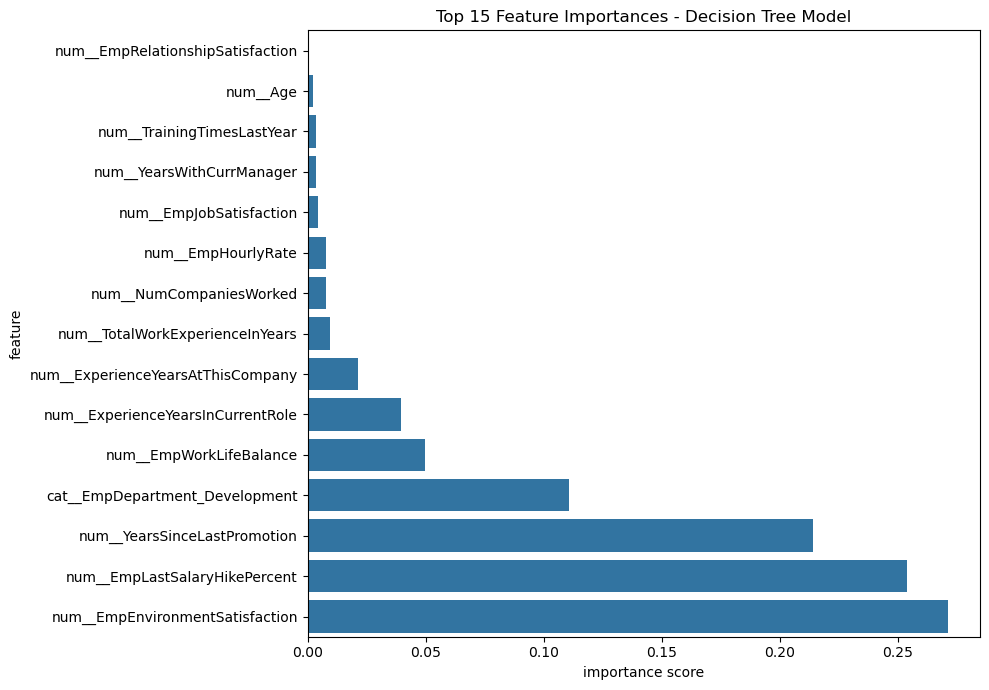

In [62]:
top_features = feature_importance.head(15).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10,7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="feature"
)

plt.title("Top 15 Feature Importances - Decision Tree Model")
plt.xlabel("importance score")
plt.ylabel("feature")
plt.tight_layout()
plt.show()

### Feature Importance Analysis – Conclusion

The Tuned Decision Tree model found that Employee Environment Satisfaction, Salary Hike Percentage, and Time Since Last Promotion are the three most important features for predicting employee performance. The Development department and Work-Life Balance are also important.

**Business Implication:** HR teams can focus on employee satisfaction, fair salary hikes, and timely promotions to help improve employee performance. These results show patterns in the data but do not prove that these factors directly cause better performance.

## Final Model Evaluation

We evaluate the selected Tuned Decision Tree model using a confusion matrix and classification report to understand its prediction performance for each employee performance rating.

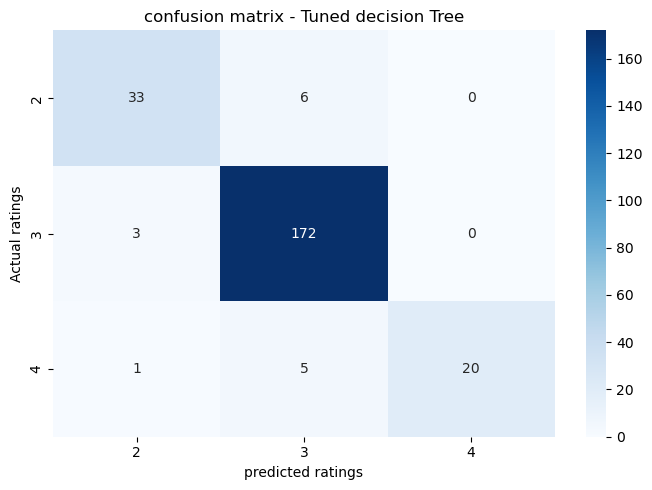

classification report:
              precision    recall  f1-score   support

           2       0.89      0.85      0.87        39
           3       0.94      0.98      0.96       175
           4       1.00      0.77      0.87        26

    accuracy                           0.94       240
   macro avg       0.94      0.87      0.90       240
weighted avg       0.94      0.94      0.94       240



In [63]:
from sklearn.metrics import confusion_matrix,classification_report
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_final = best_dt_model.predict(x_test)

cm = confusion_matrix(y_test,y_pred_final)

plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_dt_model.classes_,
    yticklabels=best_dt_model.classes_
)

plt.title("confusion matrix - Tuned decision Tree")
plt.xlabel("predicted ratings")
plt.ylabel("Actual ratings")
plt.tight_layout()
plt.show()

print("classification report:")
print(classification_report(y_test,y_pred_final,zero_division=0))


### Final Model Evaluation 

The Tuned Decision Tree achieved 93.75% accuracy on the test dataset. It performed best for Rating 3, with a recall of 98%. For Rating 4, precision was 100%, but recall was 77%, meaning some employees with Rating 4 were missed. Overall, the model performed well, with scope to improve predictions for Rating 4.